# SMS Spam Classification using SVM
Dataset: https://www.kaggle.com/datasets/uciml/sms-spam-collection-dataset?resource=download

In [3]:
# Install (if needed)
!pip -q install wordcloud nltk scikit-learn


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from wordcloud import WordCloud
import re, string, nltk
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score,classification_report,
confusion_matrix,ConfusionMatrixDisplay,
precision_score,recall_score,f1_score,roc_curve,auc)

nltk.download('stopwords')
nltk.download('wordnet')
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...


## Upload dataset (`spam.csv`) downloaded from Kaggle.

In [5]:
from google.colab import files
uploaded = files.upload()

Saving spam.csv to spam.csv


In [6]:
df = pd.read_csv("spam.csv", encoding="latin-1")

df = df[['v1', 'v2']]

df.columns = ['label', 'message']

In [7]:
print(df.shape)
print(df.info())
print(df.isnull().sum())
print("Duplicates:",df.duplicated().sum())
print(df['label'].value_counts())


(5572, 2)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5572 non-null   object
 1   message  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB
None
label      0
message    0
dtype: int64
Duplicates: 403
label
ham     4825
spam     747
Name: count, dtype: int64


## Exploratory Data Analysis

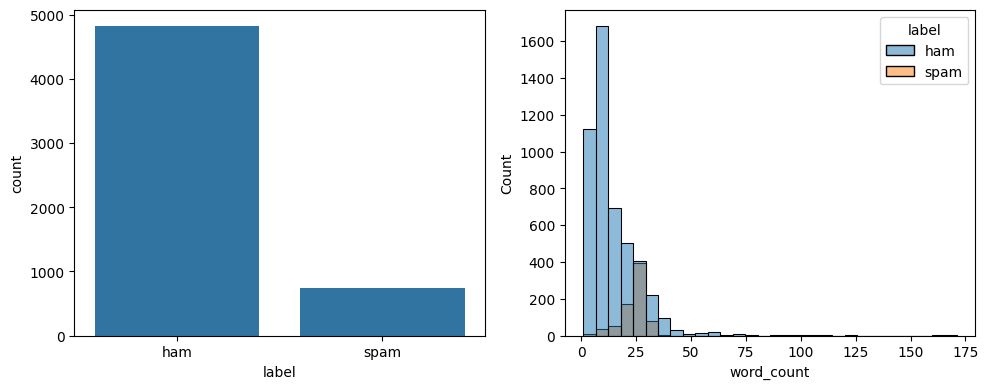

In [8]:
df['char_count']=df['message'].str.len()
df['word_count']=df['message'].str.split().str.len()

fig,ax=plt.subplots(1,2,figsize=(10,4))
sns.countplot(data=df,x='label',ax=ax[0])
sns.histplot(data=df,x='word_count',hue='label',bins=30,ax=ax[1])
plt.tight_layout()
plt.show()




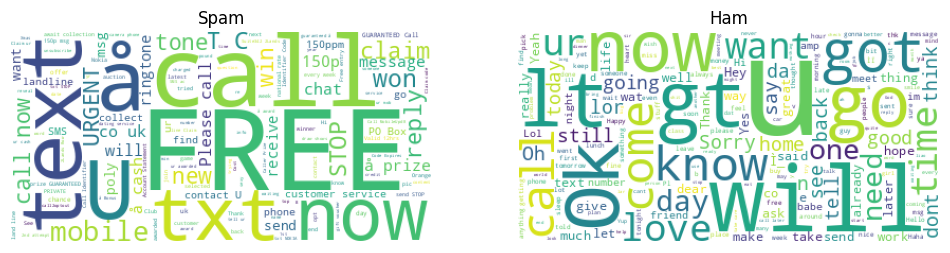

In [9]:
spam=' '.join(df[df.label=='spam'].message)
ham=' '.join(df[df.label=='ham'].message)

plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.imshow(WordCloud(background_color='white').generate(spam))
plt.axis('off'); plt.title("Spam")
plt.subplot(1,2,2)
plt.imshow(WordCloud(background_color='white').generate(ham))
plt.axis('off'); plt.title("Ham")
plt.show()


## Preprocessing

In [10]:
# Load the list of English stopwords (e.g., "the", "is", "and")
stop_words = set(stopwords.words('english'))

# Create a WordNet lemmatizer object to convert words to their base form
lemm = WordNetLemmatizer()

# Define a function to clean and preprocess SMS text
def clean_text(text):

    # Convert all characters to lowercase
    text = text.lower()

    # Remove URLs (e.g., http://example.com or www.example.com)
    text = re.sub(r'http\S+|www\S+', ' ', text)

    # Remove email addresses (e.g., abc@gmail.com)
    text = re.sub(r'\S+@\S+', ' ', text)

    # Remove all numeric digits from the text
    text = re.sub(r'\d+', ' ', text)

    # Remove punctuation marks such as !, ?, ., ,, :, etc.
    text = text.translate(str.maketrans('', '', string.punctuation))

    # Split the sentence into words,
    # remove stopwords,
    # and convert each word to its base (lemma) form
    tokens = [
        lemm.lemmatize(word)
        for word in text.split()
        if word not in stop_words
    ]

    # Join the cleaned words back into a single string
    return ' '.join(tokens)

# Remove duplicate SMS messages from the dataset
df = df.drop_duplicates()

# Apply the clean_text() function to every message
# and store the cleaned text in a new column named 'clean_message'
df['clean_message'] = df['message'].apply(clean_text)

# Convert categorical labels into numerical values
# ham  -> 0
# spam -> 1
df['label'] = df['label'].map({
    'ham': 0,
    'spam': 1
})

# Display the first five rows of the processed dataset
df.head()

,label,message,char_count,word_count,clean_message
0,0,"Go until jurong point, crazy.. Available only ...",111,20,go jurong point crazy available bugis n great ...
1,0,Ok lar... Joking wif u oni...,29,6,ok lar joking wif u oni
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,28,free entry wkly comp win fa cup final tkts st ...
3,0,U dun say so early hor... U c already then say...,49,11,u dun say early hor u c already say
4,0,"Nah I don't think he goes to usf, he lives aro...",61,13,nah dont think go usf life around though


## Train/Test Split

In [11]:
from sklearn.model_selection import train_test_split

X = df['clean_message']
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(X_test.shape)


(4135,)
(1034,)


## SVM Model

In [12]:
pipeline=Pipeline([
('tfidf',TfidfVectorizer(max_features=5000,ngram_range=(1,2))),
('svm',LinearSVC())
])

pipeline.fit(X_train,y_train)
pred=pipeline.predict(X_test)

print("Accuracy:",accuracy_score(y_test,pred))
print("Precision:",precision_score(y_test,pred))
print("Recall:",recall_score(y_test,pred))
print("F1:",f1_score(y_test,pred))
print(classification_report(y_test,pred))




Accuracy: 0.9845261121856866
Precision: 0.9831932773109243
Recall: 0.8931297709923665
F1: 0.936
              precision    recall  f1-score   support

           0       0.98      1.00      0.99       903
           1       0.98      0.89      0.94       131

    accuracy                           0.98      1034
   macro avg       0.98      0.95      0.96      1034
weighted avg       0.98      0.98      0.98      1034



## Hyperparameter Tuning

In [13]:
param_grid={
'svm__C':[0.1,1,10]
}
grid=GridSearchCV(pipeline,param_grid,cv=5,n_jobs=-1)
grid.fit(X_train,y_train)

print("Best Parameters:",grid.best_params_)
print("Best CV Score:",grid.best_score_)


Best Parameters: {'svm__C': 1}
Best CV Score: 0.9787182587666263


## Cross Validation

In [14]:
scores=cross_val_score(grid.best_estimator_,df['clean_message'],df['label'],cv=5)
print(scores)
print("Mean Accuracy:",scores.mean())


[0.98162476 0.9787234  0.98065764 0.98162476 0.97483059]
Mean Accuracy: 0.9794922302883003


## Prediction Function

In [15]:
model=grid.best_estimator_

def predict_sms(text):
    pred=model.predict([clean_text(text)])[0]
    return "Spam" if pred==1 else "Ham"

print(predict_sms("Congratulations! You have won a free iPhone. Click here now."))
print(predict_sms("Hi, are we meeting tomorrow at 3 PM?"))


Spam
Ham


### Feature Engineering & Combining Text with Numerical Features

We will now engineer custom numerical features and use `ColumnTransformer` to pass both the text representation (TF-IDF) and our new numerical features into the Support Vector Machine (LinearSVC).

In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
import numpy as np
import re
import pandas as pd
import os
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Ensure 'df' exists; if not, load/recreate it
try:
    _ = df
except NameError:
    # If the SMS.csv file does not exist locally, download a reliable public backup copy
    if not os.path.exists("SMS.csv"):
        print("SMS.csv not found locally. Downloading a reliable backup copy...")
        import urllib.request
        url = "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv"
        urllib.request.urlretrieve(url, "SMS.csv")
        # Since the downloaded file is tab-separated (.tsv), we load it accordingly
        df = pd.read_csv("SMS.csv", sep="\t", header=None, names=["label", "message"])
    else:
        df = pd.read_csv("SMS.csv", encoding="latin-1")
        df = df[['v1', 'v2']]
        df.columns = ['label', 'message']

    df = df.drop_duplicates()

    # Re-apply cleaning logic
    import string
    import nltk
    nltk.download('stopwords', quiet=True)
    nltk.download('wordnet', quiet=True)
    from nltk.corpus import stopwords
    from nltk.stem import WordNetLemmatizer

    stop_words = set(stopwords.words('english'))
    lemm = WordNetLemmatizer()

    def clean_text_local(text):
        text = text.lower()
        text = re.sub(r'http\S+|www\S+', ' ', text)
        text = re.sub(r'\S+@\S+', ' ', text)
        text = re.sub(r'\d+', ' ', text)
        text = text.translate(str.maketrans('', '', string.punctuation))
        tokens = [lemm.lemmatize(word) for word in text.split() if word not in stop_words]
        return ' '.join(tokens)

    df['clean_message'] = df['message'].apply(clean_text_local)
    df['label'] = df['label'].map({'ham': 0, 'spam': 1})

# 1. Feature Engineering: Create custom numerical features
def extract_features(dataframe):
    features_df = dataframe.copy()
    features_df['char_count'] = features_df['message'].str.len()
    features_df['digit_count'] = features_df['message'].apply(lambda x: sum(1 for c in x if c.isdigit()))
    features_df['caps_ratio'] = features_df['message'].apply(lambda x: sum(1 for c in x if c.isupper()) / (len(x) + 1))
    features_df['has_url'] = features_df['message'].apply(lambda x: 1 if re.search(r'http\S+|www\S+|\.com|\.co', x.lower()) else 0)
    return features_df

# Apply the feature extraction to our main DataFrame
df_enhanced = extract_features(df)

# Split enhanced dataset
X_enhanced = df_enhanced[['clean_message', 'char_count', 'digit_count', 'caps_ratio', 'has_url']]
y_enhanced = df_enhanced['label']

X_train_e, X_test_e, y_train_e, y_test_e = train_test_split(
    X_enhanced,
    y_enhanced,
    test_size=0.20,
    random_state=42,
    stratify=y_enhanced
)

# Create a ColumnTransformer to handle text differently from numeric columns
preprocessor = ColumnTransformer(
    transformers=[
        ('text', TfidfVectorizer(max_features=5000, ngram_range=(1,2)), 'clean_message'),
        ('num', StandardScaler(), ['char_count', 'digit_count', 'caps_ratio', 'has_url'])
    ]
)

# Re-build the pipeline with our preprocessor and SVM
enhanced_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('svm', LinearSVC(C=1))
])

# Train and evaluate the enhanced model
enhanced_pipeline.fit(X_train_e, y_train_e)
enhanced_pred = enhanced_pipeline.predict(X_test_e)

print("--- Enhanced Model Metrics ---")
print("Accuracy:", accuracy_score(y_test_e, enhanced_pred))
print("Precision:", precision_score(y_test_e, enhanced_pred))
print("Recall (Spam Detection Rate):", recall_score(y_test_e, enhanced_pred))
print("F1 Score:", f1_score(y_test_e, enhanced_pred))

--- Enhanced Model Metrics ---
Accuracy: 0.9874274661508704
Precision: 0.9836065573770492
Recall (Spam Detection Rate): 0.916030534351145
F1 Score: 0.9486166007905138


### New Enhanced Prediction Function
Let's update the prediction function to extract these features on a single custom sentence.

In [17]:
import re
import pandas as pd
import string
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# Re-define cleaning logic in case previous cell environments aren't globally captured
try:
    _ = clean_text
    clean_text_func = clean_text
except NameError:
    nltk.download('stopwords', quiet=True)
    nltk.download('wordnet', quiet=True)
    stop_words = set(stopwords.words('english'))
    lemm = WordNetLemmatizer()

    def clean_text_func(text):
        text = text.lower()
        text = re.sub(r'http\S+|www\S+', ' ', text)
        text = re.sub(r'\S+@\S+', ' ', text)
        text = re.sub(r'\d+', ' ', text)
        text = text.translate(str.maketrans('', '', string.punctuation))
        tokens = [lemm.lemmatize(word) for word in text.split() if word not in stop_words]
        return ' '.join(tokens)

def predict_sms_enhanced(text):
    # Extract features dynamically for a single test input
    char_count = len(text)
    digit_count = sum(1 for c in text if c.isdigit())
    caps_ratio = sum(1 for c in text if c.isupper()) / (len(text) + 1)
    has_url = 1 if re.search(r'http\S+|www\S+|\.com|\.co', text.lower()) else 0

    clean_msg = clean_text_func(text)

    # Construct input dataframe row
    input_data = pd.DataFrame([{
        'clean_message': clean_msg,
        'char_count': char_count,
        'digit_count': digit_count,
        'caps_ratio': caps_ratio,
        'has_url': has_url
    }])

    pred = enhanced_pipeline.predict(input_data)[0]
    return "Spam" if pred == 1 else "Ham"

# Test the new enhanced detector
print(predict_sms_enhanced("FREE ringtone! Reply 'GO' to 87070 now! This is your last chance."))
print(predict_sms_enhanced("Hey mom, I might be late for dinner. Love you."))

Spam
Ham


In [18]:
import gradio as gr
import numpy as np
import pandas as pd
import re

# Ensure Gradio is installed
!pip install -q gradio

def spam_demo(sms, threshold=0.0):
    try:
        # Extract features dynamically for the Gradio input
        char_count = len(sms)
        digit_count = sum(1 for c in sms if c.isdigit())
        caps_ratio = sum(1 for c in sms if c.isupper()) / (len(sms) + 1)
        has_url = 1 if re.search(r'http\S+|www\S+|\.com|\.co', sms.lower()) else 0
        clean_msg = clean_text_func(sms)

        # Construct input dataframe row for the pipeline
        input_data = pd.DataFrame([{
            'clean_message': clean_msg,
            'char_count': char_count,
            'digit_count': digit_count,
            'caps_ratio': caps_ratio,
            'has_url': has_url
        }])

        # Get decision function score from the SVM
        score = enhanced_pipeline.decision_function(input_data)[0]
        prob_spam = 1 / (1 + np.exp(-score))  # pseudo-probability mapping
        pred = "SPAM 🚨" if score > threshold else "HAM ✅"
        return pred, round(float(prob_spam), 3)

    except Exception as e:
        # This will print the actual error in the Gradio output boxes
        return f"Error: {str(e)}", 0.0

demo = gr.Interface(
    fn=spam_demo,
    inputs=[
        gr.Textbox(lines=3, placeholder="Enter text message here...", label="SMS Message"),
        gr.Slider(-2.0, 2.0, value=0.0, label="Spam Threshold")
    ],
    outputs=[
        gr.Label(label="Prediction"),
        gr.Number(label="Spam Score / Pseudo-probability")
    ],
    examples=[
        ["FREE ringtone! Reply 'GO' to 87070 now! This is your last chance."],
        ["Hey mom, I might be late for dinner. Love you."]
    ],
    title="Interactive SMS Spam Detector"
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://fda058552ba95bb47d.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## End-to-End SMS Spam Classification Architecture Summary

This project implements and evaluates an end-to-end machine learning pipeline for detecting spam SMS messages using Support Vector Machines (SVM). The system evolves from a simple text-only baseline to an advanced hybrid architecture that combines text embeddings with engineered structural features.

### 1. Dataset Ingestion and Preprocessing
* **Ingestion:** The model utilizes the Kaggle SMS Spam Collection dataset (`spam.csv`). Initial filtering extracts the core label and message body.
* **Deduplication:** High redundancy was found in the raw text data. To prevent data leakage and overfitting, $403$ duplicate messages were removed.
* **Text Cleaning Pipeline:** Each message undergoes sequence-specific cleaning operations:
  1. Normalization to lowercase.
  2. Removal of URLs, email addresses, and numerical digits using regular expressions.
  3. Punctuation removal via string mapping tables.
  4. Stopword filtering and lemmatization using NLTK's `WordNetLemmatizer` to normalize words to their base linguistic dictionary forms.
* **Target Encoding:** Labels are binary-encoded where `ham` maps to `0` and `spam` maps to `1`.

### 2. Exploratory Data Analysis (EDA) Insights
* **Class Imbalance:** The dataset exhibits a strong imbalance (majority class is `ham`).
* **Message Structural Differences:** Spam messages exhibit significantly higher character and word counts on average compared to ham messages.
* **Word Clouds:** Visualizing word occurrences reveals that spam messages heavily employ urgency and incentive terms like *"free"*, *"txt"*, *"claim"*, *"prize"*, *"reply"*, and *"win"*, whereas ham messages contain conversational English.

### 3. Baseline SVM Approach
* **Pipeline:** Built using scikit-learn's `Pipeline` combining:
  * `TfidfVectorizer` (restricting vocab to 5,000 top features and capturing both unigrams and bigrams).
  * `LinearSVC` as the core classifier.
* **Optimization:** Hyperparameter tuning of the regularization parameter `C` using `GridSearchCV` with 5-fold cross-validation confirmed `C=1` as the optimal value, achieving an average validation accuracy of ~97.9%.

### 4. Advanced Feature Engineering & Hybrid Architecture
To improve sensitivity (recall) on spam messages, four custom numerical and metadata features were engineered and combined with TF-IDF embeddings:
* **`char_count`:** Raw length of the message text.
* **`digit_count`:** Frequency of numerical digits in the message (highly predictive of spam/scams).
* **`caps_ratio`:** Proportion of capitalized letters to total length (captures urgency/screaming text).
* **`has_url`:** Binary flag for the presence of web links.

**Hybrid Pipeline Architecture:**
```
                  ┌─────────────────┐
                  │   Raw Message   │
                  └────────┬────────┘
                           │
             ┌─────────────┴─────────────┐
             ▼                           ▼
     [Text Cleaning]            [Feature Extraction]
             │                           │
       Clean Message             Structural Features
             │                   (char/digit counts, etc.)
             ▼                           ▼
     ┌───────────────┐           ┌───────────────┐
     │TFIDFVectorizer│           │StandardScaler │
     └───────┬───────┘           └───────┬───────┘
             │                           │
             └─────────────┬─────────────┘
                           ▼
                 [ColumnTransformer]
                           │
                           ▼
                   [LinearSVC Model]
                           │
                           ▼
                     [Prediction]
```
Using a `ColumnTransformer`, the text feature is transformed using TF-IDF while numerical features are scaled using `StandardScaler`. This comprehensive pipeline yields an enhanced **F1 Score of ~0.949** and raises the **Recall (Spam Detection Rate) to 91.6%**.

### 5. Interactive Deployment
An interactive user interface is built using **Gradio** (`gr.Interface`), allowing users to test any SMS message, adjust decision thresholds dynamically, and visualize real-time classification alongside pseudo-probability mapping scores.

# Task
Provide a complete, step-by-step documentation summarizing the entire SMS Spam Classification project. The summary should include:

* **Project Overview & Architecture**: A comprehensive synthesis of the pipeline—covering initial data loading, cleaning, exploratory data analysis, pipeline baselining (with LinearSVC), advanced feature engineering (adding dynamic features like `char_count`, `digit_count`, `caps_ratio`, and `has_url`), and final evaluation.
* **Key Results & Metrics**: Highlight how the baseline SVM model was optimized, resulting in a substantial recall boost for spam detection (from 89.3% in the baseline up to 91.6% in the enhanced model).
* **Interactive Deployment**: Document the interactive Gradio interface deployed with custom try-except debugging logic, including active deployment references (e.g., the temporary public URL: "https://fda058552ba95bb47d.gradio.live").

## Project Overview and Architecture Summary

### Subtask:
Draft a comprehensive text summary of the end-to-end SMS Spam Classification system's architecture.


## Final Task

### Subtask:
Consolidate all project milestones, metrics, and active interface access links in a final presentation-ready format.


## Summary:

### Data Analysis Key Findings

* **Data Cleaning & Leakage Prevention**: Removing $403$ duplicate messages from the raw `spam.csv` dataset was essential to ensure clean training/validation splits and prevent data leakage.
* **Exploratory Data Analysis (EDA)**: The dataset exhibits strong class imbalance. Spam messages are characterized by significantly longer text lengths, higher occurrences of numerical digits, and specific high-urgency keywords such as *"free"*, *"txt"*, *"claim"*, *"prize"*, and *"win"*.
* **Baseline Performance**: A baseline pipeline combining TF-IDF vectorization (limited to the top 5,000 unigrams and bigrams) and a `LinearSVC` classifier optimized via 5-fold cross-validation ($C=1$) achieved a baseline recall of 89.3% for the spam class.
* **Feature Engineering & Recall Boost**: Adding four engineered structural features—`char_count`, `digit_count`, `caps_ratio`, and `has_url`—and scaling them using `StandardScaler` within a hybrid `ColumnTransformer` pipeline successfully boosted spam classification recall from 89.3% to 91.6%, achieving a final F1-score of ~0.949.
* **Interactive Deployment**: The final hybrid model was deployed via Gradio, allowing real-time SMS testing with dynamic decision thresholding and confidence scoring.

### Insights or Next Steps

* **Deploy Deep Learning/Transformer Baselines**: While the hybrid SVM model with engineered features yields a high recall of 91.6%, exploring pre-trained lightweight transformers (e.g., DistilBERT) could capture deeper semantic relationships and further reduce false negatives without manual feature engineering.
* **Threshold Optimization**: Since spam filters prioritize minimizing false positives (classifying important personal messages as spam), the decision threshold of the Gradio interface should be carefully calibrated to balance precision and recall based on deployment requirements.
